## Config

### Imports

In [1]:
import os
import math
import pandas as pd
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from IPython.display import display
import seaborn as sns

### loading data

In [2]:
data_path = os.path.join("data", "output", "processed_projetos_2025_2026.csv")
df = pd.read_csv(data_path, sep=";", encoding='utf-8-sig')
print(df.shape)
df.head()

(153, 27)


,lattes_id,professor,ano_inicio,ano_conclusao,projeto,descricao,situacao,natureza,alunos_envolvidos,integrantes,...,edital_ou_chamada,coordenador,valor_financiamento,financiador,tipo_bolsa,area_pgcomp,topico_pesquisa,palavras_chave,cooperacao_internacional,resumo_executivo
0,9.222610e+13,Bruno Pereira dos Santos,2024.0,NaN,Sistemas Resilientes para Ambientes Inteligent...,Situação: Em andamento; Natureza: Pesquisa. Al...,Em andamento,Pesquisa,Graduação: (4) / Mestrado acadêmico: (2) / Dou...,Bruno Pereira dos Santos - Integrante / Paulo ...,...,NaN,Paulo H. L. Rettore,NaN,['Conselho Nacional de Desenvolvimento Científ...,NaN,Ciência de Dados e Banco de Dados,Sistemas Resilientes,"['Sistemas Resilientes', 'Qualidade de Dados',...",NaN,O projeto aborda a qualidade dos dados e a con...
1,9.222610e+13,Bruno Pereira dos Santos,2024.0,NaN,Projeto ARGUS,Descrição: O aumento exponencial no volume de ...,Em andamento,Pesquisa,NaN,Bruno Pereira dos Santos - Integrante / Maycon...,...,NaN,Gustavo Bittencourt Figueiredo,NaN,[],Produtividade,Redes de Computadores e Sistemas Distribuídos,Computação Quântica,"['Computação Quântica', 'Veículos Autônomos', ...",NaN,O projeto visa desenvolver um framework para a...
2,9.222610e+13,Bruno Pereira dos Santos,2023.0,NaN,Aprendizado de Máquina Federado para Internet ...,Descrição: Os ecossistemas de Internet das Coi...,Em andamento,Pesquisa,Mestrado acadêmico: (2) Doutorado: (2),Bruno Pereira dos Santos - Integrante / Heitor...,...,NaN,Heitor S Ramos,NaN,['Fundação de Amparo à Pesquisa do Estado de M...,Formação Acadêmica,Inteligência Artificial e Aprendizado de Máquina,Aprendizado Federado para Internet das Coisas,"['Aprendizado Federado', 'Internet das Coisas'...",NaN,O projeto investiga a extração de conhecimento...
3,9.222610e+13,Bruno Pereira dos Santos,2023.0,NaN,Big Data Geocode: Uma aplicação de inteligênci...,Situação: Em andamento; Natureza: Pesquisa. In...,Em andamento,Pesquisa,NaN,Bruno Pereira dos Santos - Coordenador / Robes...,...,NaN,Bruno Pereira dos Santos,NaN,[],NaN,Inteligência Artificial e Aprendizado de Máquina,Geocodificação de Eventos em Saúde,"['Geocodificação', 'Eventos em Saúde', 'Proces...",NaN,A aplicação de inteligência computacional e pr...
4,5.075736e+15,Cássio Vinicius Serafim Prazeres,2023.0,NaN,CPA/IA - Uma Plataforma Digital Aberta Multius...,Descrição: O objetivo desta proposta é apresen...,Em andamento,Pesquisa,NaN,Cássio Vinicius Serafim Prazeres - Integrante ...,...,NaN,Ricardo Araujo Rios,NaN,[],Produtividade,Ciência de Dados e Banco de Dados,Inteligência Artificial Industrial,"['Inteligência Artificial', 'IA', 'Indústria 4...",NaN,O projeto visa desenvolver uma plataforma digi...


## Analysis

### Brief

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 153 entries, 0 to 152
Data columns (total 27 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lattes_id                 153 non-null    float64
 1   professor                 153 non-null    str    
 2   ano_inicio                153 non-null    float64
 3   ano_conclusao             51 non-null     float64
 4   projeto                   153 non-null    str    
 5   descricao                 153 non-null    str    
 6   situacao                  153 non-null    str    
 7   natureza                  153 non-null    str    
 8   alunos_envolvidos         97 non-null     str    
 9   integrantes               153 non-null    str    
 10  financiadores             74 non-null     str    
 11  descricao_limpa           153 non-null    str    
 12  edital                    24 non-null     str    
 13  qtd_graduacao             153 non-null    float64
 14  qtd_mestrado         

In [4]:
df.isna().sum()

lattes_id                     0
professor                     0
ano_inicio                    0
ano_conclusao               102
projeto                       0
descricao                     0
situacao                      0
natureza                      0
alunos_envolvidos            56
integrantes                   0
financiadores                79
descricao_limpa               0
edital                      129
qtd_graduacao                 0
qtd_mestrado                  0
qtd_doutorado                 0
total_alunos                  0
edital_ou_chamada           112
coordenador                  29
valor_financiamento         139
financiador                  29
tipo_bolsa                   69
area_pgcomp                  29
topico_pesquisa              29
palavras_chave               29
cooperacao_internacional    142
resumo_executivo             32
dtype: int64

In [5]:
df["ano_conclusao"] = df["ano_conclusao"].astype("Int64")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 153 entries, 0 to 152
Data columns (total 27 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lattes_id                 153 non-null    float64
 1   professor                 153 non-null    str    
 2   ano_inicio                153 non-null    float64
 3   ano_conclusao             51 non-null     Int64  
 4   projeto                   153 non-null    str    
 5   descricao                 153 non-null    str    
 6   situacao                  153 non-null    str    
 7   natureza                  153 non-null    str    
 8   alunos_envolvidos         97 non-null     str    
 9   integrantes               153 non-null    str    
 10  financiadores             74 non-null     str    
 11  descricao_limpa           153 non-null    str    
 12  edital                    24 non-null     str    
 13  qtd_graduacao             153 non-null    float64
 14  qtd_mestrado         

In [6]:
columns = df.columns.tolist()
print(columns)

['lattes_id', 'professor', 'ano_inicio', 'ano_conclusao', 'projeto', 'descricao', 'situacao', 'natureza', 'alunos_envolvidos', 'integrantes', 'financiadores', 'descricao_limpa', 'edital', 'qtd_graduacao', 'qtd_mestrado', 'qtd_doutorado', 'total_alunos', 'edital_ou_chamada', 'coordenador', 'valor_financiamento', 'financiador', 'tipo_bolsa', 'area_pgcomp', 'topico_pesquisa', 'palavras_chave', 'cooperacao_internacional', 'resumo_executivo']


## Comparando quantidade de projetos em cada ano

### executados 
isso indica aqueles que ou comecaram ou terminaram ou estiveram rodando naquele ano

In [7]:
# em 2025
ly_df = df.loc[df["ano_inicio"] < 2026]
print(f"{ly_df.shape}\n")
ly_df.head(3)

(153, 27)



,lattes_id,professor,ano_inicio,ano_conclusao,projeto,descricao,situacao,natureza,alunos_envolvidos,integrantes,...,edital_ou_chamada,coordenador,valor_financiamento,financiador,tipo_bolsa,area_pgcomp,topico_pesquisa,palavras_chave,cooperacao_internacional,resumo_executivo
0,9.222610e+13,Bruno Pereira dos Santos,2024.0,<NA>,Sistemas Resilientes para Ambientes Inteligent...,Situação: Em andamento; Natureza: Pesquisa. Al...,Em andamento,Pesquisa,Graduação: (4) / Mestrado acadêmico: (2) / Dou...,Bruno Pereira dos Santos - Integrante / Paulo ...,...,NaN,Paulo H. L. Rettore,NaN,['Conselho Nacional de Desenvolvimento Científ...,NaN,Ciência de Dados e Banco de Dados,Sistemas Resilientes,"['Sistemas Resilientes', 'Qualidade de Dados',...",NaN,O projeto aborda a qualidade dos dados e a con...
1,9.222610e+13,Bruno Pereira dos Santos,2024.0,<NA>,Projeto ARGUS,Descrição: O aumento exponencial no volume de ...,Em andamento,Pesquisa,NaN,Bruno Pereira dos Santos - Integrante / Maycon...,...,NaN,Gustavo Bittencourt Figueiredo,NaN,[],Produtividade,Redes de Computadores e Sistemas Distribuídos,Computação Quântica,"['Computação Quântica', 'Veículos Autônomos', ...",NaN,O projeto visa desenvolver um framework para a...
2,9.222610e+13,Bruno Pereira dos Santos,2023.0,<NA>,Aprendizado de Máquina Federado para Internet ...,Descrição: Os ecossistemas de Internet das Coi...,Em andamento,Pesquisa,Mestrado acadêmico: (2) Doutorado: (2),Bruno Pereira dos Santos - Integrante / Heitor...,...,NaN,Heitor S Ramos,NaN,['Fundação de Amparo à Pesquisa do Estado de M...,Formação Acadêmica,Inteligência Artificial e Aprendizado de Máquina,Aprendizado Federado para Internet das Coisas,"['Aprendizado Federado', 'Internet das Coisas'...",NaN,O projeto investiga a extração de conhecimento...


In [8]:
print(ly_df["ano_conclusao"].unique())
print(ly_df["ano_inicio"].unique())

<IntegerArray>
[<NA>, 2026, 2025]
Length: 3, dtype: Int64
[2024. 2023. 2016. 2014. 2022. 2009. 2003. 2018. 2017. 2015. 2013. 2021.
 2020. 2019.]


In [9]:
# 2026
ty_df = df.loc[(df["situacao"] == "Em andamento") | (df["ano_conclusao"] != 2025)]
print(f"{ty_df.shape}\n")
ty_df.head(3)

(121, 27)



,lattes_id,professor,ano_inicio,ano_conclusao,projeto,descricao,situacao,natureza,alunos_envolvidos,integrantes,...,edital_ou_chamada,coordenador,valor_financiamento,financiador,tipo_bolsa,area_pgcomp,topico_pesquisa,palavras_chave,cooperacao_internacional,resumo_executivo
0,9.222610e+13,Bruno Pereira dos Santos,2024.0,<NA>,Sistemas Resilientes para Ambientes Inteligent...,Situação: Em andamento; Natureza: Pesquisa. Al...,Em andamento,Pesquisa,Graduação: (4) / Mestrado acadêmico: (2) / Dou...,Bruno Pereira dos Santos - Integrante / Paulo ...,...,NaN,Paulo H. L. Rettore,NaN,['Conselho Nacional de Desenvolvimento Científ...,NaN,Ciência de Dados e Banco de Dados,Sistemas Resilientes,"['Sistemas Resilientes', 'Qualidade de Dados',...",NaN,O projeto aborda a qualidade dos dados e a con...
1,9.222610e+13,Bruno Pereira dos Santos,2024.0,<NA>,Projeto ARGUS,Descrição: O aumento exponencial no volume de ...,Em andamento,Pesquisa,NaN,Bruno Pereira dos Santos - Integrante / Maycon...,...,NaN,Gustavo Bittencourt Figueiredo,NaN,[],Produtividade,Redes de Computadores e Sistemas Distribuídos,Computação Quântica,"['Computação Quântica', 'Veículos Autônomos', ...",NaN,O projeto visa desenvolver um framework para a...
2,9.222610e+13,Bruno Pereira dos Santos,2023.0,<NA>,Aprendizado de Máquina Federado para Internet ...,Descrição: Os ecossistemas de Internet das Coi...,Em andamento,Pesquisa,Mestrado acadêmico: (2) Doutorado: (2),Bruno Pereira dos Santos - Integrante / Heitor...,...,NaN,Heitor S Ramos,NaN,['Fundação de Amparo à Pesquisa do Estado de M...,Formação Acadêmica,Inteligência Artificial e Aprendizado de Máquina,Aprendizado Federado para Internet das Coisas,"['Aprendizado Federado', 'Internet das Coisas'...",NaN,O projeto investiga a extração de conhecimento...


In [10]:
print(ty_df["ano_conclusao"].unique())
print(ty_df["ano_inicio"].unique())

<IntegerArray>
[<NA>, 2026]
Length: 2, dtype: Int64
[2024. 2023. 2016. 2014. 2022. 2009. 2003. 2018. 2017. 2015. 2013. 2021.
 2020.]


In [11]:
df["ano_conclusao"].unique()

<IntegerArray>
[<NA>, 2026, 2025]
Length: 3, dtype: Int64

In [12]:
df["ano_inicio"].unique()

array([2024., 2023., 2016., 2014., 2022., 2009., 2003., 2018., 2017.,
       2015., 2013., 2021., 2020., 2019.])

## projetos rodando

In [16]:
import ast

In [19]:
df_exploded.columns

Index(['lattes_id', 'professor', 'ano_inicio', 'ano_conclusao', 'projeto',
       'descricao', 'situacao', 'natureza', 'alunos_envolvidos', 'integrantes',
       'financiadores', 'descricao_limpa', 'edital', 'qtd_graduacao',
       'qtd_mestrado', 'qtd_doutorado', 'total_alunos', 'edital_ou_chamada',
       'coordenador', 'valor_financiamento', 'financiador', 'tipo_bolsa',
       'area_pgcomp', 'topico_pesquisa', 'palavras_chave',
       'cooperacao_internacional', 'resumo_executivo', 'financiadores_lista'],
      dtype='str')

<Axes: xlabel='ano_inicio'>

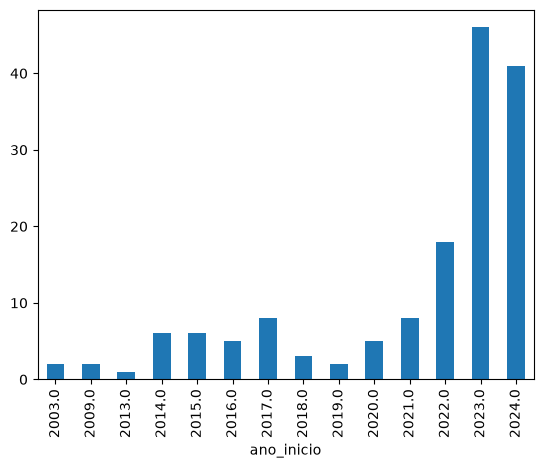

In [24]:
pbt = df.groupby(["ano_inicio"]).size()
pbt.plot(kind="bar", x="ano_inicio", stacked=True)

In [23]:
df['financiador'] = (
    df['financiador'].fillna("['Não informado']").replace('[]', "['Não informado']")
)

df['financiadores_lista'] = df['financiador'].apply(ast.literal_eval)

df_exploded = df.explode('financiadores_lista').reset_index(drop=True)

# Tabela cruzada
tabela = pd.crosstab(
    df_exploded['ano_inicio'], 
    # df_exploded['financiadores_lista']
)

# Plot do gráfico empilhado
tabela.plot(kind='bar', stacked=True, figsize=(12, 6))

TypeError: crosstab() missing 1 required positional argument: 'columns'

In [ ]:
df.plot(x="")

In [37]:
df["professor"].unique()

<StringArray>
[         'Bruno Pereira dos Santos',  'Cássio Vinicius Serafim Prazeres',
 'Christina von Flach Garcia Chavez',            'Daniela Barreiro Claro',
        'Eduardo Santana de Almeida',            'Frederico Araujo Durão',
    'Gustavo Bittencourt Figueiredo',  'Islame Felipe da Costa Fernandes',
             'Ivan do Carmo Machado',        'Leobino Nascimento Sampaio',
      'Luciano Rebouças de Oliveira',     'Manoel Gomes de Mendonça Neto',
   'Marlo Vieira dos Santos e Souza',       'Maycon Leone Maciel Peixoto',
            'Rafael Augusto de Melo',               'Ricardo Araújo Rios',
    'Rita Suzana Pitangueira Maciel',  'Robespierre Dantas da Rocha Pita',
             'Tatiane Nogueira Rios',   'Gecynalda Soares da Silva Gomes']
Length: 20, dtype: str

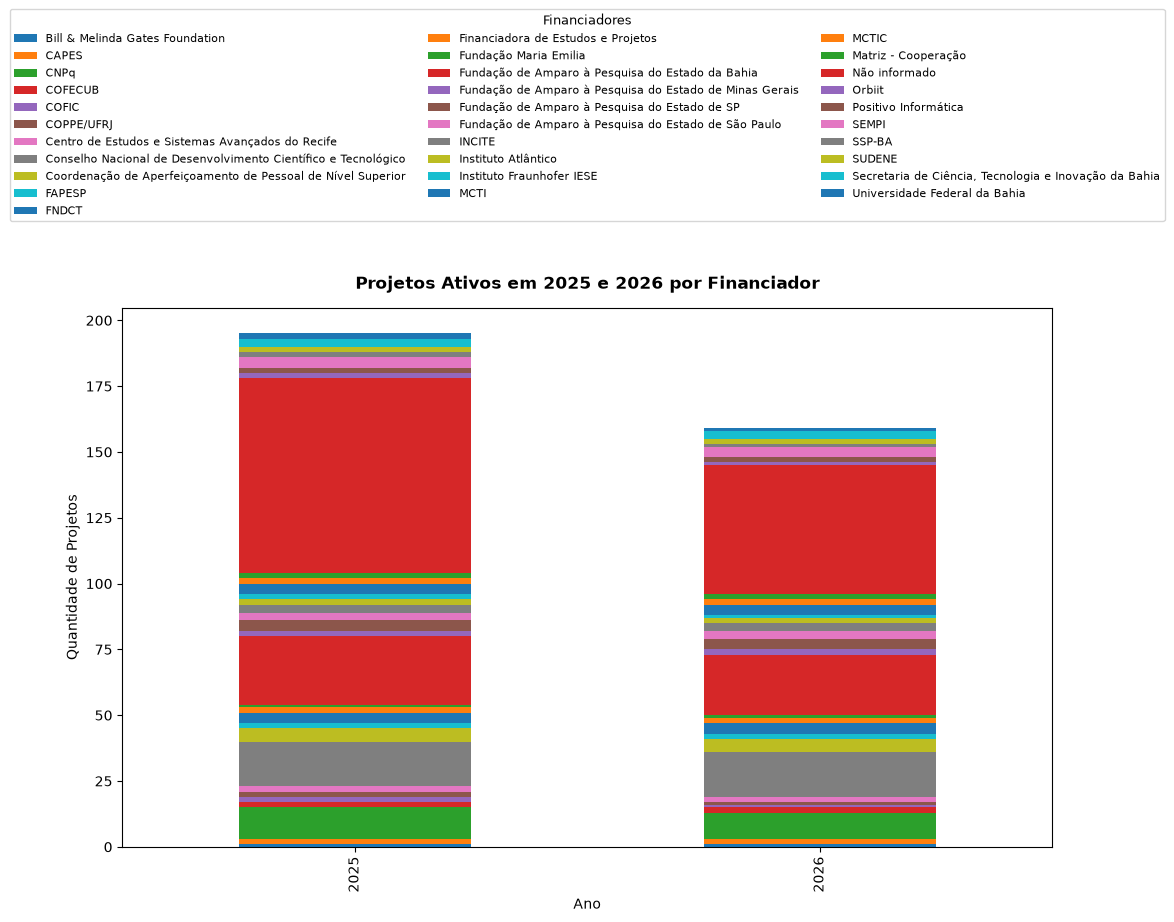

In [27]:
# Unir os dois conjuntos resetando os índices para evitar duplicatas
df_ativos = pd.concat([df_2025, df_2026], ignore_index=True)

# Tabela cruzada
tabela = pd.crosstab(df_ativos['Ano'], df_ativos['financiadores_lista'])

# Plot do gráfico empilhado

# 1. Gerar o gráfico a partir da tabela cruzada
fig, ax = plt.subplots(figsize=(12, 7))
tabela.plot(kind='bar', stacked=True, ax=ax)

# 2. Configurar o Título (posicionado abaixo da legenda)
ax.set_title(
    'Projetos Ativos em 2025 e 2026 por Financiador',
    y=1.02,
    fontsize=12,
    fontweight='bold',
)

# 3. Configurar a Legenda Horizontal acima do título
ax.legend(
    title='Financiadores',
    loc='lower center',  # Alinha a base da legenda ao ponto de ancoragem
    bbox_to_anchor=(0.5, 1.15),  # Eleva a legenda para cima do título
    ncol=3,  # Quantidade de colunas horizontais
    fontsize=8,
    title_fontsize=9,
)

# 4. Rótulos e exibição
plt.xlabel('Ano')
plt.ylabel('Quantidade de Projetos')

# O bbox_inches='tight' garante que a legenda superior não seja cortada
plt.savefig('grafico_projetos.png', bbox_inches='tight', dpi=300)
plt.show()

### projetos por professor

In [28]:
prof_grouped = df.groupby(
    ["professor"],
).size().reset_index()
prof_grouped.columns = ["professor", "quantidade_projetos"]
prof_grouped

,professor,quantidade_projetos
0,Bruno Pereira dos Santos,12
1,Christina von Flach Garcia Chavez,6
2,Cássio Vinicius Serafim Prazeres,12
3,Daniela Barreiro Claro,7
4,Eduardo Santana de Almeida,9
5,Frederico Araujo Durão,15
6,Gecynalda Soares da Silva Gomes,2
7,Gustavo Bittencourt Figueiredo,21
8,Islame Felipe da Costa Fernandes,7
9,Ivan do Carmo Machado,5


In [29]:
nomes_abreviados = prof_grouped["professor"].str.split(" ").str[-1] + ", " + prof_grouped["professor"].str[0] + "."
nomes_abreviados = nomes_abreviados.values.tolist()
nomes_abreviados

['Santos, B.',
 'Chavez, C.',
 'Prazeres, C.',
 'Claro, D.',
 'Almeida, E.',
 'Durão, F.',
 'Gomes, G.',
 'Figueiredo, G.',
 'Fernandes, I.',
 'Machado, I.',
 'Sampaio, L.',
 'Oliveira, L.',
 'Neto, M.',
 'Souza, M.',
 'Peixoto, M.',
 'Melo, R.',
 'Rios, R.',
 'Maciel, R.',
 'Pita, R.',
 'Rios, T.']

C:\Users\ferna\AppData\Local\Temp\ipykernel_14152\2494123223.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(prof_grouped["professor"].tolist(), rotation=50, ha="right")


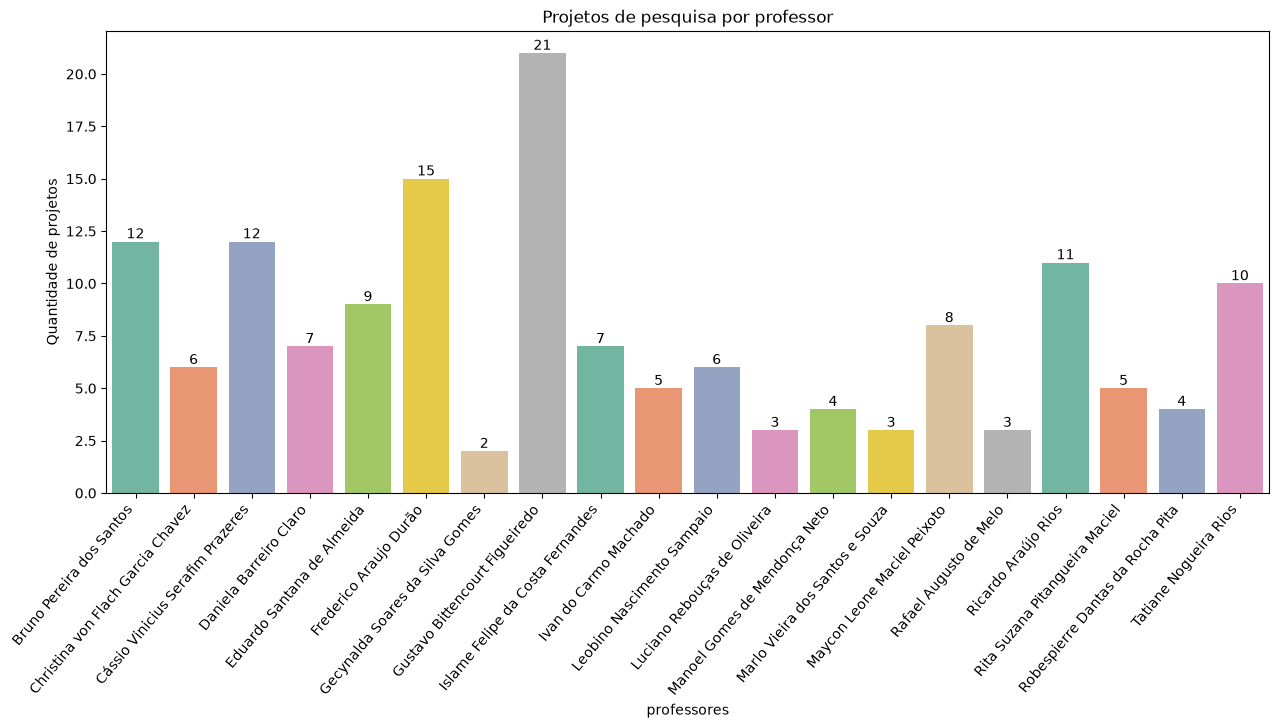

In [41]:
fig, ax = plt.subplots(figsize=(15, 6))
sns.barplot(
    prof_grouped,
    hue="professor",
    x="professor",
    y="quantidade_projetos",
    palette="Set2",
    ax=ax,
)
for c in ax.containers:
  ax.bar_label(c, fontsize=10)

ax.set_xlabel("professores")

# Adicionado rotation=40 e ha='right'
ax.set_xticklabels(prof_grouped["professor"].tolist(), rotation=50, ha="right")

ax.set_ylabel("Quantidade de projetos")
plt.title("Projetos de pesquisa por professor")
plt.show()

##### por ano

In [42]:
# 2026
prof_grouped_ty = ty_df.groupby(
    ["professor"],
).size().reset_index()
prof_grouped_ty.columns = ["professor", "quantidade_projetos"]
prof_grouped_ty

,professor,quantidade_projetos
0,Bruno Pereira dos Santos,8
1,Christina von Flach Garcia Chavez,6
2,Cássio Vinicius Serafim Prazeres,10
3,Daniela Barreiro Claro,5
4,Eduardo Santana de Almeida,7
5,Frederico Araujo Durão,7
6,Gecynalda Soares da Silva Gomes,2
7,Gustavo Bittencourt Figueiredo,21
8,Islame Felipe da Costa Fernandes,5
9,Ivan do Carmo Machado,5


In [43]:
# 2025
prof_grouped_ly = ly_df.groupby(
    ["professor"],
).size().reset_index()
prof_grouped_ly.columns = ["professor", "quantidade_projetos"]
prof_grouped_ly

,professor,quantidade_projetos
0,Bruno Pereira dos Santos,12
1,Christina von Flach Garcia Chavez,6
2,Cássio Vinicius Serafim Prazeres,12
3,Daniela Barreiro Claro,7
4,Eduardo Santana de Almeida,9
5,Frederico Araujo Durão,15
6,Gecynalda Soares da Silva Gomes,2
7,Gustavo Bittencourt Figueiredo,21
8,Islame Felipe da Costa Fernandes,7
9,Ivan do Carmo Machado,5


### Orientandos

analisar quais professores possui mais orientandos em seus projetos (validar melhor estrategia para isso)

In [44]:
df.head(3)

,lattes_id,professor,ano_inicio,ano_conclusao,projeto,descricao,situacao,natureza,alunos_envolvidos,integrantes,...,coordenador,valor_financiamento,financiador,tipo_bolsa,area_pgcomp,topico_pesquisa,palavras_chave,cooperacao_internacional,resumo_executivo,financiadores_lista
0,9.222610e+13,Bruno Pereira dos Santos,2024.0,<NA>,Sistemas Resilientes para Ambientes Inteligent...,Situação: Em andamento; Natureza: Pesquisa. Al...,Em andamento,Pesquisa,Graduação: (4) / Mestrado acadêmico: (2) / Dou...,Bruno Pereira dos Santos - Integrante / Paulo ...,...,Paulo H. L. Rettore,NaN,['Conselho Nacional de Desenvolvimento Científ...,NaN,Ciência de Dados e Banco de Dados,Sistemas Resilientes,"['Sistemas Resilientes', 'Qualidade de Dados',...",NaN,O projeto aborda a qualidade dos dados e a con...,[Conselho Nacional de Desenvolvimento Científi...
1,9.222610e+13,Bruno Pereira dos Santos,2024.0,<NA>,Projeto ARGUS,Descrição: O aumento exponencial no volume de ...,Em andamento,Pesquisa,NaN,Bruno Pereira dos Santos - Integrante / Maycon...,...,Gustavo Bittencourt Figueiredo,NaN,['Não informado'],Produtividade,Redes de Computadores e Sistemas Distribuídos,Computação Quântica,"['Computação Quântica', 'Veículos Autônomos', ...",NaN,O projeto visa desenvolver um framework para a...,[Não informado]
2,9.222610e+13,Bruno Pereira dos Santos,2023.0,<NA>,Aprendizado de Máquina Federado para Internet ...,Descrição: Os ecossistemas de Internet das Coi...,Em andamento,Pesquisa,Mestrado acadêmico: (2) Doutorado: (2),Bruno Pereira dos Santos - Integrante / Heitor...,...,Heitor S Ramos,NaN,['Fundação de Amparo à Pesquisa do Estado de M...,Formação Acadêmica,Inteligência Artificial e Aprendizado de Máquina,Aprendizado Federado para Internet das Coisas,"['Aprendizado Federado', 'Internet das Coisas'...",NaN,O projeto investiga a extração de conhecimento...,[Fundação de Amparo à Pesquisa do Estado de Mi...


### Financiamentos
- analisar quais sao as naturezas de financiamentos
- analisar se ha projetos sem financiamento
- analisar cooperacao internacional

In [53]:
def extrair_modalidade(texto):
  if pd.isna(texto):
    return []
  modalidades = []
  txt = str(texto)
  if 'Auxílio financeiro' in txt or 'Auxilio financeiro' in txt:
    modalidades.append('Auxílio Financeiro')
  if 'Bolsa' in txt:
    modalidades.append('Bolsa')
  if 'Cooperação' in txt or 'Cooperacao' in txt:
    modalidades.append('Cooperação')
  if not modalidades:
    modalidades.append('Outro / Não especificado')
  return modalidades

In [ ]:
df['modalidades'] = df['financiadores'].apply(extrair_modalidade)
df_exploded = df.explode('modalidades').reset_index(drop=True)

def rodou_no_ano(row, ano):
  if pd.isna(row['ano_inicio']) or row['ano_inicio'] > ano:
    return False
  if pd.isna(row['ano_conclusao']):
    return True
  return row['ano_conclusao'] >= ano


df_2025 = df_exploded[
    df_exploded.apply(lambda r: rodou_no_ano(r, 2025), axis=1)
].copy()
df_2025['Ano'] = 2025

df_2026 = df_exploded[
    df_exploded.apply(lambda r: rodou_no_ano(r, 2026), axis=1)
].copy()
df_2026['Ano'] = 2026

df_ativos_mod = pd.concat([df_2025, df_2026], ignore_index=True)

# 3. Tabela cruzada (Ano x Modalidade)
tabela_mod = pd.crosstab(df_ativos_mod['Ano'], df_ativos_mod['modalidades'])

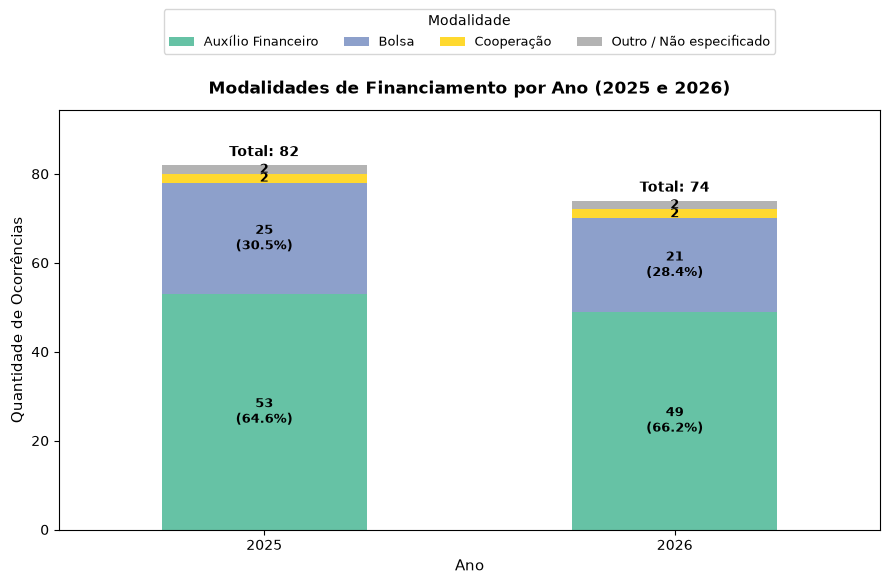

In [65]:
# 1. Tabela cruzada (Ano x Modalidade)
tabela_mod = pd.crosstab(df_ativos_mod['Ano'], df_ativos_mod['modalidades'])

# 2. Plotagem
fig, ax = plt.subplots(figsize=(9, 6))
tabela_mod.plot(kind='bar', stacked=True, ax=ax, colormap='Set2')

# 3. Adicionar os rótulos internos (% e valor bruto) e o total no topo
colunas = tabela_mod.columns.tolist()
anos = tabela_mod.index.tolist()

for j, ano in enumerate(anos):
  altura_acumulada = 0
  total_ano = tabela_mod.loc[ano].sum()

  for col in colunas:
    val = tabela_mod.loc[ano, col]
    if val > 0:
      pct = (val / total_ano) * 100
      y_pos = altura_acumulada + (val / 2)

      # Formatação do texto (exibe valor e %)
      texto = f'{val}\n({pct:.1f}%)' if val >= 5 else f'{val}'
      ax.text(
          j,
          y_pos,
          texto,
          ha='center',
          va='center',
          fontweight='bold',
          fontsize=9,
      )

    altura_acumulada += val

  # Exibe o total acima da barra
  ax.text(
      j,
      altura_acumulada + 2,
      f'Total: {altura_acumulada}',
      ha='center',
      fontweight='bold',
      fontsize=10,
  )

# 4. Configurações visuais
ax.set_title(
    'Modalidades de Financiamento por Ano (2025 e 2026)',
    y=1.02,
    fontsize=12,
    fontweight='bold',
)
ax.set_xlabel('Ano', fontsize=11)
ax.set_ylabel('Quantidade de Ocorrências', fontsize=11)
ax.set_ylim(0, max(tabela_mod.sum(axis=1)) * 1.15)

ax.legend(
    title='Modalidade',
    loc='lower center',
    bbox_to_anchor=(0.5, 1.12),
    ncol=4,
    fontsize=9,
    title_fontsize=10,
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

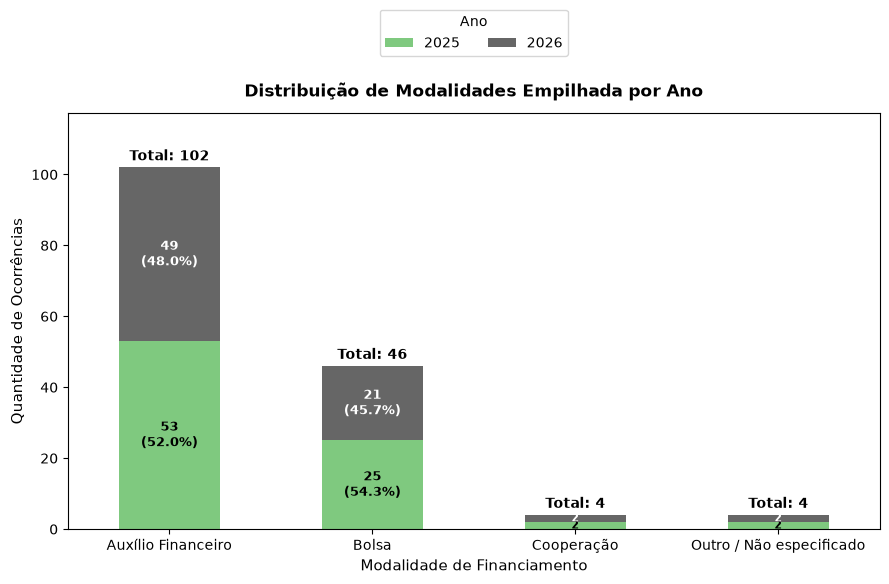

In [68]:
# 1. Tabela cruzada (Modalidade no eixo X, empilhado por Ano)
tabela_mod = pd.crosstab(df_ativos_mod['modalidades'], df_ativos_mod['Ano'])

# 2. Plotagem com a cor original (colormap='Accent')
fig, ax = plt.subplots(figsize=(9, 6))
tabela_mod.plot(kind='bar', stacked=True, ax=ax, colormap='Accent')

anos = tabela_mod.columns.tolist()  # [2025, 2026]
modalidades = tabela_mod.index.tolist()

for j, mod in enumerate(modalidades):
  altura_acumulada = 0
  total_mod = tabela_mod.loc[mod].sum()

  for col in anos:
    val = tabela_mod.loc[mod, col]
    if val > 0:
      pct = (val / total_mod) * 100
      y_pos = altura_acumulada + (val / 2)
      cor_texto = 'white' if col == 2026 else 'black'

      # Fatias maiores (>= 5): exibe valor + porcentagem
      if val >= 5:
        texto = f'{val}\n({pct:.1f}%)'
        fonte = 9
      # Fatias menores (< 5): exibe apenas o valor bruto para evitar sobreposição
      else:
        texto = f'{val}'
        fonte = 8

      ax.text(
          j,
          y_pos,
          texto,
          ha='center',
          va='center',
          fontweight='bold',
          fontsize=fonte,
          color=cor_texto,
      )

    altura_acumulada += val

  # Exibe o total acima de cada barra
  ax.text(
      j,
      altura_acumulada + 2,
      f'Total: {altura_acumulada}',
      ha='center',
      fontweight='bold',
      fontsize=10,
  )

# 3. Ajustes de layout
ax.set_title(
    'Distribuição de Modalidades Empilhada por Ano',
    y=1.02,
    fontsize=12,
    fontweight='bold',
)
ax.set_xlabel('Modalidade de Financiamento', fontsize=11)
ax.set_ylabel('Quantidade de Ocorrências', fontsize=11)
ax.set_ylim(0, max(tabela_mod.sum(axis=1)) * 1.15)

ax.legend(
    title='Ano',
    loc='lower center',
    bbox_to_anchor=(0.5, 1.12),
    ncol=2,
    fontsize=10,
    title_fontsize=10,
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [61]:
# 2. Identificar se há financiamento registrado
def verificar_financiamento(val):
  if pd.isna(val) or val == '[]' or val == "['Não informado']":
    return 'Sem Financiamento'
  try:
    parsed = ast.literal_eval(val)
    if isinstance(parsed, list) and len(parsed) == 0:
      return 'Sem Financiamento'
    return 'Com Financiamento'
  except Exception:
    return 'Sem Financiamento'


df['status_financiamento'] = df['financiador'].apply(verificar_financiamento)


# 3. Filtrar projetos ativos em 2025 e 2026
def rodou_no_ano(row, ano):
  if pd.isna(row['ano_inicio']) or row['ano_inicio'] > ano:
    return False
  if pd.isna(row['ano_conclusao']):
    return True
  return row['ano_conclusao'] >= ano


df_2025 = df[df.apply(lambda r: rodou_no_ano(r, 2025), axis=1)].copy()
df_2025['Ano'] = 2025

df_2026 = df[df.apply(lambda r: rodou_no_ano(r, 2026), axis=1)].copy()
df_2026['Ano'] = 2026

df_ativos_status = pd.concat([df_2025, df_2026], ignore_index=True)

# 4. Tabela cruzada (Ano x Status)
tabela_status = pd.crosstab(
    df_ativos_status['Ano'], df_ativos_status['status_financiamento']
)


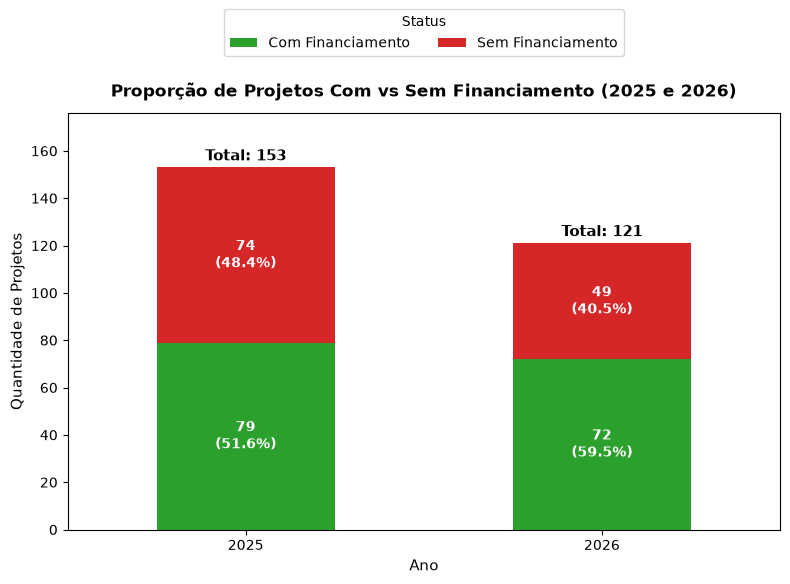

In [62]:
# 5. Plotagem do gráfico empilhado
fig, ax = plt.subplots(figsize=(8, 6))
cores = ['#2ca02c', '#d62728']  # Verde para Com, Vermelho para Sem

tabela_status[['Com Financiamento', 'Sem Financiamento']].plot(
    kind='bar', stacked=True, color=cores, ax=ax
)

# 6. Adicionar rótulos de Quantidade e Porcentagem dentro das barras
for col in ['Com Financiamento', 'Sem Financiamento']:
  for j, year in enumerate([2025, 2026]):
    val = tabela_status.loc[year, col]
    total_year = tabela_status.loc[year].sum()
    pct = (val / total_year) * 100

    # Posição Y no meio da fatia da barra
    if col == 'Com Financiamento':
      y_pos = val / 2
    else:
      y_pos = tabela_status.loc[year, 'Com Financiamento'] + (val / 2)

    ax.text(
        j,
        y_pos,
        f'{val}\n({pct:.1f}%)',
        ha='center',
        va='center',
        color='white',
        fontweight='bold',
        fontsize=10,
    )

# 7. Adicionar o total no topo de cada barra
totals = tabela_status.sum(axis=1)
for idx, total in zip(range(len(totals)), totals):
  ax.text(
      idx,
      total + 3,
      f'Total: {total}',
      ha='center',
      fontweight='bold',
      fontsize=11,
  )

# Ajustes de layout, título e legenda horizontal superior
ax.set_title(
    'Proporção de Projetos Com vs Sem Financiamento (2025 e 2026)',
    y=1.02,
    fontsize=12,
    fontweight='bold',
)
ax.set_xlabel('Ano', fontsize=11)
ax.set_ylabel('Quantidade de Projetos', fontsize=11)
ax.set_ylim(0, max(totals) * 1.15)

ax.legend(
    title='Status',
    loc='lower center',
    bbox_to_anchor=(0.5, 1.12),
    ncol=2,
    fontsize=10,
    title_fontsize=10,
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Linhas de pesquisa
- analisar quais sao as linhas de pesquisa
    - ha alguma(s) linha(s) de pesquisa com maior quantitativo de projetos?
- analisar se ha correlacao entre tempo medio de duracao similares entre projetos de mesma linha de pesquisa
    - com coordenador igual ou distinto
- analisar correlacao entre financiamento e linha de pesquisa: ha alguma linha que possui mais financiamento? 

#### quantidade de linhas de pesquisa

In [80]:
sns.set_theme(style='whitegrid')
df['area_pgcomp_clean'] = df['area_pgcomp'].fillna('Não identificado')

# 2. Função para verificar projetos ativos em cada ano
def rodou_no_ano(row, ano):
  if pd.isna(row['ano_inicio']) or row['ano_inicio'] > ano:
    return False
  if pd.isna(row['ano_conclusao']):
    return True
  return row['ano_conclusao'] >= ano


# 3. Filtrar projetos ativos em 2025 e 2026
df_2025 = df[df.apply(lambda r: rodou_no_ano(r, 2025), axis=1)].copy()
df_2025['Ano'] = 2025

df_2026 = df[df.apply(lambda r: rodou_no_ano(r, 2026), axis=1)].copy()
df_2026['Ano'] = 2026

df_ativos_linha = pd.concat([df_2025, df_2026], ignore_index=True)
df_ativos_linha = df_ativos_linha[
    df_ativos_linha['area_pgcomp_clean'] != 'Não informado'
]

# 4. Tabela cruzada (Linha de Pesquisa x Ano) ordenada pelo total
tabela_linha_ano = pd.crosstab(
    df_ativos_linha['area_pgcomp_clean'], df_ativos_linha['Ano']
)
tabela_linha_ano['Total'] = tabela_linha_ano.sum(axis=1)
tabela_linha_ano = tabela_linha_ano.sort_values(
    by='Total', ascending=True
).drop(columns=['Total'])

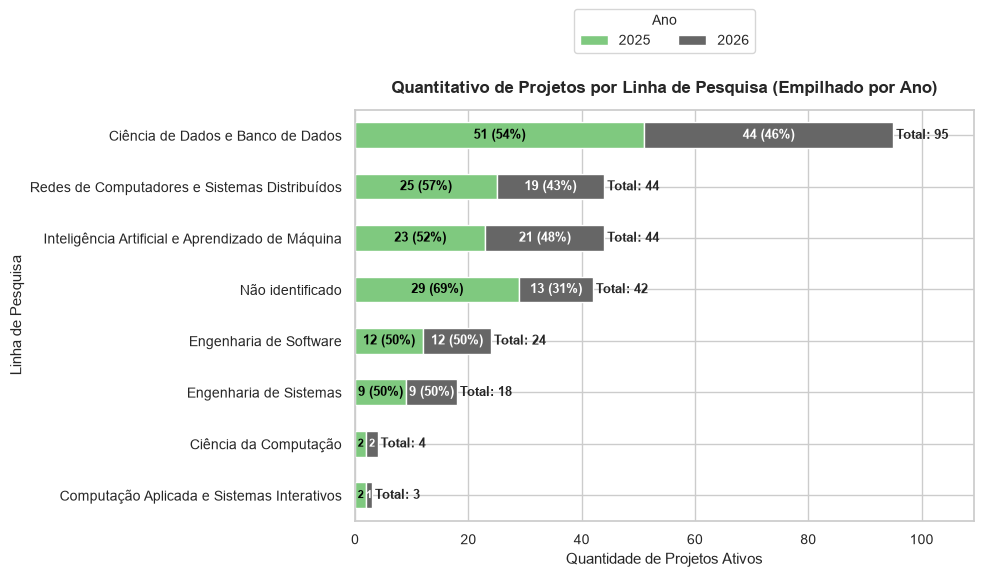

In [82]:

# 5. Plotagem
fig, ax = plt.subplots(figsize=(10, 6))
tabela_linha_ano.plot(kind='barh', stacked=True, ax=ax, colormap='Accent')

anos = tabela_linha_ano.columns.tolist()  # [2025, 2026]
linhas = tabela_linha_ano.index.tolist()

# 6. Adicionar rótulos internos (% e valor bruto) e totais nas pontas
for i, linha in enumerate(linhas):
  cum_x = 0
  total_linha = tabela_linha_ano.loc[linha].sum()

  for col in anos:
    val = tabela_linha_ano.loc[linha, col]
    if val > 0:
      pct = (val / total_linha) * 100
      x_pos = cum_x + (val / 2)
      cor_texto = 'white' if col == 2026 else 'black'

      # Se a fatia for grande (>= 5), exibe valor + %; caso contrário, exibe apenas o valor
      if val >= 5:
        texto = f'{val} ({pct:.0f}%)'
        fonte = 9
      else:
        texto = f'{val}'
        fonte = 8

      ax.text(
          x_pos,
          i,
          texto,
          ha='center',
          va='center',
          fontweight='bold',
          fontsize=fonte,
          color=cor_texto,
      )

    cum_x += val

  # Exibe o total acumulado ao lado de cada barra
  ax.text(
      cum_x + 0.5,
      i,
      f'Total: {cum_x}',
      ha='left',
      va='center',
      fontweight='bold',
      fontsize=9,
  )

# 7. Configurações visuais do gráfico
ax.set_title(
    'Quantitativo de Projetos por Linha de Pesquisa (Empilhado por Ano)',
    y=1.02,
    fontsize=12,
    fontweight='bold',
)
ax.set_xlabel('Quantidade de Projetos Ativos', fontsize=11)
ax.set_ylabel('Linha de Pesquisa', fontsize=11)
ax.set_xlim(0, max(tabela_linha_ano.sum(axis=1)) * 1.15)

ax.legend(
    title='Ano',
    loc='lower center',
    bbox_to_anchor=(0.5, 1.12),
    ncol=2,
    fontsize=10,
    title_fontsize=10,
)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.tight_layout()
plt.show()

#### duração média por linha de pesquisa


In [85]:
sns.set_theme(style='whitegrid')

# 1. Carregar os dados e calcular a duração estimada
df['area_pgcomp_clean'] = df['area_pgcomp'].fillna('Não informado')
df_linhas = df[df['area_pgcomp_clean'] != 'Não informado'].copy()

df_linhas['duracao_est'] = (
    df_linhas['ano_conclusao'].fillna(2026) - df_linhas['ano_inicio']
)

# 2. Agrupar média de duração por linha de pesquisa
dur_linha = (
    df_linhas.groupby('area_pgcomp_clean')['duracao_est'].mean().reset_index()
)
dur_linha = dur_linha.sort_values(by='duracao_est', ascending=False)
dur_linha.columns = ['Linha de Pesquisa', 'Duração Média (Anos)']


# 3. Função para converter o valor decimal de anos para "X anos e Y meses"
def format_anos_meses(val_anos):
  anos = int(val_anos)
  frac = val_anos - anos
  meses = round(frac * 12)

  if meses == 12:
    anos += 1
    meses = 0

  partes = []
  if anos == 1:
    partes.append('1 ano')
  elif anos > 1:
    partes.append(f'{anos} anos')

  if meses == 1:
    partes.append('1 mês')
  elif meses > 1:
    partes.append(f'{meses} meses')

  if not partes:
    return '0 meses'

  return ' e '.join(partes)



C:\Users\ferna\AppData\Local\Temp\ipykernel_14152\1944819445.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


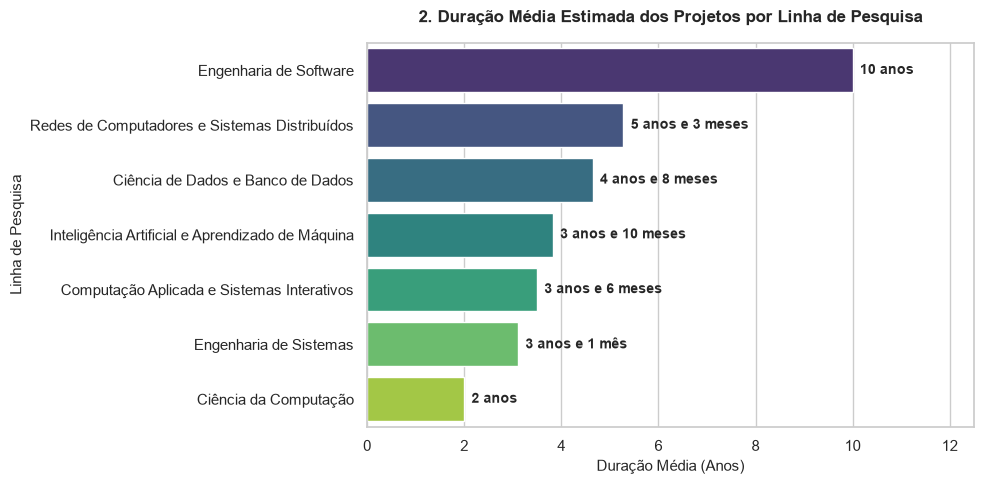

In [86]:
# 4. Plotagem do gráfico
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=dur_linha,
    y='Linha de Pesquisa',
    x='Duração Média (Anos)',
    palette='viridis',
    ax=ax,
)

# 5. Adicionar os rótulos formatados em cada barra
for i, row in dur_linha.reset_index(drop=True).iterrows():
  val = row['Duração Média (Anos)']
  texto = format_anos_meses(val)
  ax.text(
      val + 0.15,
      i,
      texto,
      va='center',
      ha='left',
      fontsize=10,
      fontweight='bold',
  )

# 6. Configurações visuais
ax.set_title(
    'Duração Média Estimada dos Projetos por Linha de Pesquisa',
    fontsize=12,
    fontweight='bold',
    pad=15,
)
ax.set_xlabel('Duração Média (Anos)', fontsize=11)
ax.set_ylabel('Linha de Pesquisa', fontsize=11)
ax.set_xlim(0, max(dur_linha['Duração Média (Anos)']) * 1.25)

plt.tight_layout()
plt.show()

#### correlação entre financiamento e linha de pesquisa

In [87]:
df['area_pgcomp_clean'] = df['area_pgcomp'].fillna('Não informado')
df_linhas = df[df['area_pgcomp_clean'] != 'Não informado'].copy()


def verificar_financiamento(val):
  if pd.isna(val) or val == '[]' or val == "['Não informado']":
    return 'Sem Financiamento'
  try:
    parsed = ast.literal_eval(val)
    if isinstance(parsed, list) and len(parsed) == 0:
      return 'Sem Financiamento'
    return 'Com Financiamento'
  except Exception:
    return 'Sem Financiamento'

In [88]:
df_linhas['status_financiamento'] = df_linhas['financiador'].apply(
    verificar_financiamento
)

# 2. Tabela cruzada ordenada pelo total
tabela_fin = pd.crosstab(
    df_linhas['area_pgcomp_clean'], df_linhas['status_financiamento']
)
tabela_fin['Total'] = tabela_fin.sum(axis=1)
tabela_fin = tabela_fin.sort_values(by='Total', ascending=True).drop(
    columns=['Total']
)

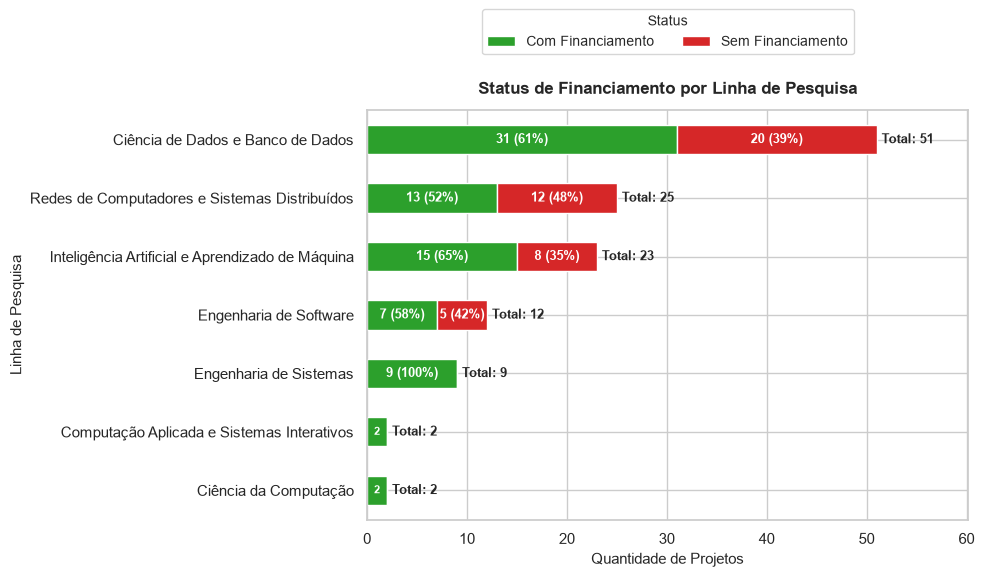

In [91]:

# 3. Plotagem do gráfico
fig, ax = plt.subplots(figsize=(10, 6))
tabela_fin[['Com Financiamento', 'Sem Financiamento']].plot(
    kind='barh', stacked=True, color=['#2ca02c', '#d62728'], ax=ax
)

# 4. Adicionar rótulos internos (% e valor bruto) e totais
for i, linha in enumerate(tabela_fin.index):
  cum_x = 0
  total_linha = tabela_fin.loc[linha].sum()
  for col in ['Com Financiamento', 'Sem Financiamento']:
    val = tabela_fin.loc[linha, col]
    if val > 0:
      pct = (val / total_linha) * 100
      x_pos = cum_x + (val / 2)

      if val >= 3:
        ax.text(
            x_pos,
            i,
            f'{val} ({pct:.0f}%)',
            ha='center',
            va='center',
            color='white',
            fontweight='bold',
            fontsize=9,
        )
      else:
        ax.text(
            x_pos,
            i,
            f'{val}',
            ha='center',
            va='center',
            color='white',
            fontweight='bold',
            fontsize=8,
        )
      cum_x += val
  ax.text(
      cum_x + 0.5,
      i,
      f'Total: {cum_x}',
      ha='left',
      va='center',
      fontweight='bold',
      fontsize=9,
  )

# 5. Ajustes de posição do Título e Legenda
ax.set_title(
    'Status de Financiamento por Linha de Pesquisa',
    y=1.02,
    fontsize=12,
    fontweight='bold',
)
ax.set_xlabel('Quantidade de Projetos', fontsize=11)
ax.set_ylabel('Linha de Pesquisa', fontsize=11)
ax.set_xlim(0, max(tabela_fin.sum(axis=1)) * 1.18)

ax.legend(
    title='Status',
    loc='lower center',
    bbox_to_anchor=(0.5, 1.12),
    ncol=2,
    fontsize=10,
    title_fontsize=10,
)

plt.tight_layout()
plt.show()

### tempo de duracao
- analisar tempo de duracao dos projetos
- analisar se ha algum orientador que demore mais nos projetos

In [93]:
# Calcular duração estimada (considerando 2026 para projetos em andamento)
df['duracao_est'] = (
    df['ano_conclusao'].fillna(2026) - df['ano_inicio']
).clip(lower=1)


# Função auxiliar para formatar anos e meses
def format_anos_meses(val_anos):
  anos = int(val_anos)
  frac = val_anos - anos
  meses = round(frac * 12)

  if meses == 12:
    anos += 1
    meses = 0

  partes = []
  if anos == 1:
    partes.append('1 ano')
  elif anos > 1:
    partes.append(f'{anos} anos')

  if meses == 1:
    partes.append('1 mês')
  elif meses > 1:
    partes.append(f'{meses} meses')

  return ' e '.join(partes) if partes else '0 meses'

#### tempo de duração

C:\Users\ferna\AppData\Local\Temp\ipykernel_14152\2786882181.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


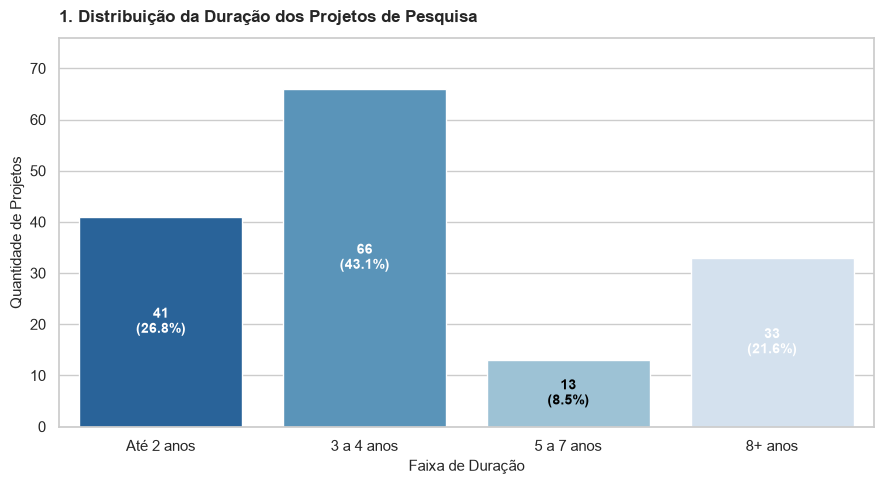

In [94]:
sns.set_theme(style='whitegrid')

# Categorização por faixas de duração
bins = [0, 2, 4, 7, 30]
labels = ['Até 2 anos', '3 a 4 anos', '5 a 7 anos', '8+ anos']
df['faixa_duracao'] = pd.cut(
    df['duracao_est'], bins=bins, labels=labels, right=True
)

dist_duracao = df['faixa_duracao'].value_counts().reset_index()
dist_duracao.columns = ['Faixa de Duração', 'Quantidade']
dist_duracao = dist_duracao.sort_values(by='Faixa de Duração')

fig1, ax1 = plt.subplots(figsize=(9, 5))
sns.barplot(
    data=dist_duracao,
    x='Faixa de Duração',
    y='Quantidade',
    palette='Blues_r',
    ax=ax1,
)

total_proj = len(df)
for p in ax1.patches:
  altura = p.get_height()
  if altura > 0:
    pct = (altura / total_proj) * 100
    ax1.annotate(
        f'{int(altura)}\n({pct:.1f}%)',
        (p.get_x() + p.get_width() / 2.0, altura / 2),
        ha='center',
        va='center',
        color='white' if altura > 20 else 'black',
        fontweight='bold',
        fontsize=10,
    )

ax1.set_title(
    'Distribuição da Duração dos Projetos de Pesquisa',
    loc='left',
    y=1.02,
    fontsize=12,
    fontweight='bold',
)
ax1.set_xlabel('Faixa de Duração', fontsize=11)
ax1.set_ylabel('Quantidade de Projetos', fontsize=11)
ax1.set_ylim(0, max(dist_duracao['Quantidade']) * 1.15)

plt.tight_layout()
plt.show()

#### duração por orientador

C:\Users\ferna\AppData\Local\Temp\ipykernel_14152\4049389624.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


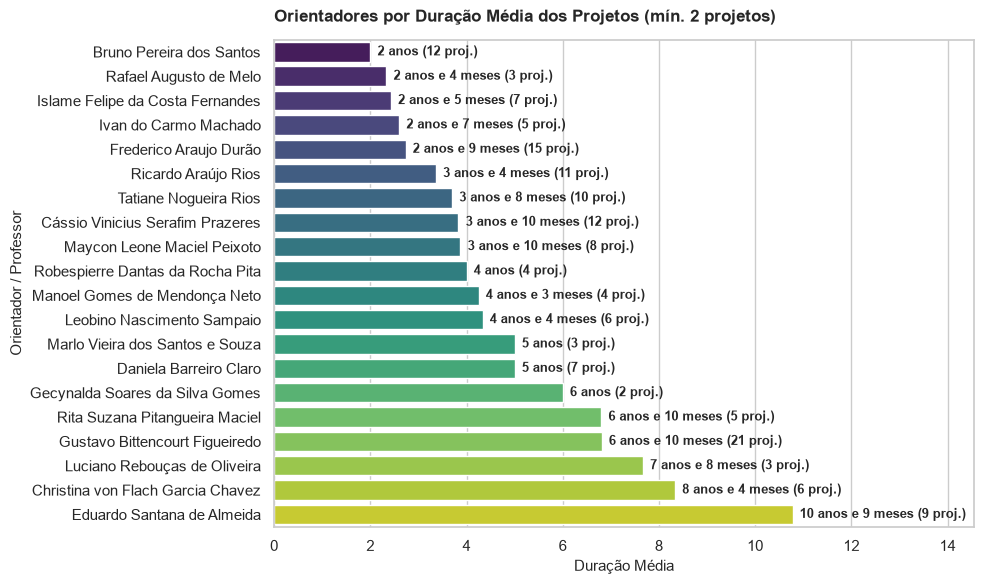

In [98]:
col_orientador = 'professor' if 'professor' in df.columns else 'coordenador'

# Filtrar orientadores com no mínimo 2 projetos cadastrados
prof_dur = (
    df.groupby(col_orientador)['duracao_est']
    .agg(['count', 'mean'])
    .reset_index()
)
prof_dur = (
    prof_dur[prof_dur['count'] >= 2]
    .sort_values(by='mean', ascending=True)
    # .head(10)
)
prof_dur['rotulo_duracao'] = prof_dur['mean'].apply(format_anos_meses)

fig2, ax2 = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=prof_dur, y=col_orientador, x='mean', palette='viridis', ax=ax2
)

for i, row in prof_dur.reset_index(drop=True).iterrows():
  val = row['mean']
  rotulo = f"{row['rotulo_duracao']} ({row['count']} proj.)"
  ax2.text(
      val + 0.15,
      i,
      rotulo,
      va='center',
      ha='left',
      fontsize=9,
      fontweight='bold',
  )

ax2.set_title(
    'Orientadores por Duração Média dos Projetos (mín. 2 projetos)',
    loc='left',
    y=1.02,
    fontsize=12,
    fontweight='bold',
)
ax2.set_xlabel('Duração Média', fontsize=11)
ax2.set_ylabel('Orientador / Professor', fontsize=11)
ax2.set_xlim(0, max(prof_dur['mean']) * 1.35)

plt.tight_layout()
plt.show()

### Internacionalizacao
- checar se ha linhas de pesquisa que puxam mais internacionalizacao ou fomento de capital estrangeiro
- checar duracao: mais curta? mais demorada? similar aos "nacionais"?
- ha algum(ns) professor(es) que tem mais projetos internacionais? ha alguma correlacao?

#### linhas com mais fomento estrageiro

In [99]:
# 2. Identificação de fomento/cooperação internacional
def classificar_escopo(row):
  texto = f"{row.get('financiador', '')} {row.get('financiadores', '')} {row.get('projeto', '')}"
  if pd.isna(texto):
    return 'Nacional'

  txt = str(texto).upper()
  keywords_int = [
      'ERASMUS',
      'EU ',
      'EUROPEAN',
      'HORIZON',
      'NSF',
      'INRIA',
      'DAAD',
      'FULBRIGHT',
      'DFG',
      'EUBR',
      'INTERNACIONAL',
      'ESTRANGEIRO',
      'FOREIGN',
      'USAID',
      'MIT',
  ]

  if any(kw in txt for kw in keywords_int):
    return 'Internacional / Estrangeiro'
  return 'Nacional'


df['escopo_fomento'] = df.apply(classificar_escopo, axis=1)

# 3. Tabela cruzada por Linha de Pesquisa
df_linhas = df[df['area_pgcomp_clean'] != 'Não informado'].copy()
tabela_escopo = pd.crosstab(
    df_linhas['area_pgcomp_clean'], df_linhas['escopo_fomento']
)
tabela_escopo['Total'] = tabela_escopo.sum(axis=1)
tabela_escopo = tabela_escopo.sort_values(by='Total', ascending=True).drop(
    columns=['Total']
)

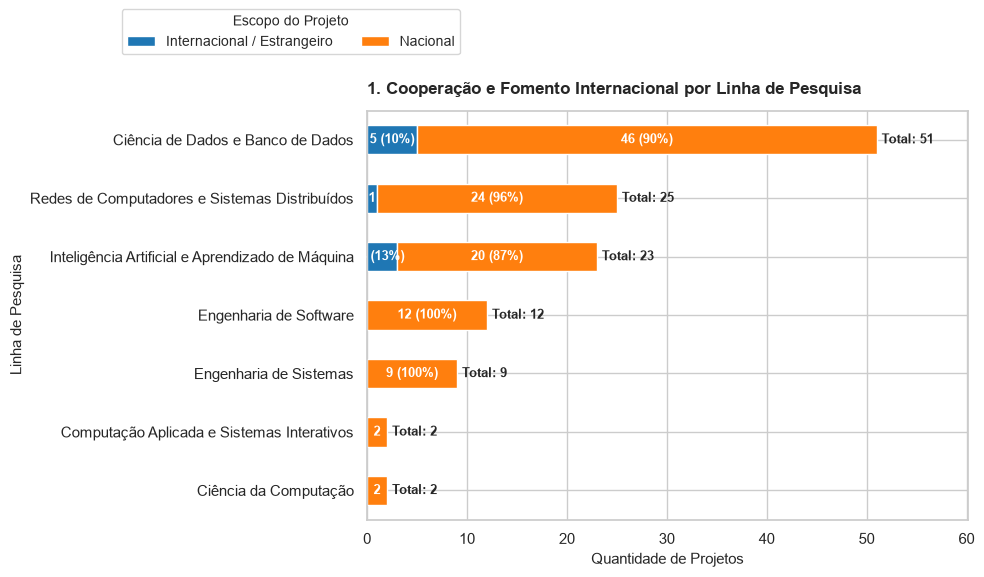

In [100]:
# 4. Plotagem
sns.set_theme(style='whitegrid')

fig, ax = plt.subplots(figsize=(10, 6))
tabela_escopo.plot(
    kind='barh', stacked=True, color=['#1f77b4', '#ff7f0e'], ax=ax
)

for i, linha in enumerate(tabela_escopo.index):
  cum_x = 0
  total_linha = tabela_escopo.loc[linha].sum()
  for col in tabela_escopo.columns:
    val = tabela_escopo.loc[linha, col]
    if val > 0:
      pct = (val / total_linha) * 100
      x_pos = cum_x + (val / 2)
      texto = f'{val} ({pct:.0f}%)' if val >= 3 else f'{val}'
      ax.text(
          x_pos,
          i,
          texto,
          ha='center',
          va='center',
          color='white',
          fontweight='bold',
          fontsize=9,
      )
      cum_x += val
  ax.text(
      cum_x + 0.5,
      i,
      f'Total: {cum_x}',
      ha='left',
      va='center',
      fontweight='bold',
      fontsize=9,
  )

ax.set_title(
    '1. Cooperação e Fomento Internacional por Linha de Pesquisa',
    loc='left',
    x=0,
    y=1.02,
    fontsize=12,
    fontweight='bold',
)
ax.set_xlabel('Quantidade de Projetos', fontsize=11)
ax.set_ylabel('Linha de Pesquisa', fontsize=11)
ax.set_xlim(0, max(tabela_escopo.sum(axis=1)) * 1.18)

# Legenda alinhada à esquerda sobre os rótulos do eixo Y
ax.legend(
    title='Escopo do Projeto',
    loc='lower left',
    bbox_to_anchor=(-0.42, 1.12),
    ncol=2,
    fontsize=10,
    title_fontsize=10,
)

plt.tight_layout()
plt.show()

#### durações

In [102]:
# 1. Função para conversão legível de duração
def format_anos_meses(val_anos):
  anos = int(val_anos)
  frac = val_anos - anos
  meses = round(frac * 12)
  if meses == 12:
    anos += 1
    meses = 0

  partes = []
  if anos == 1:
    partes.append('1 ano')
  elif anos > 1:
    partes.append(f'{anos} anos')

  if meses == 1:
    partes.append('1 mês')
  elif meses > 1:
    partes.append(f'{meses} meses')

  return ' e '.join(partes) if partes else '0 meses'

In [103]:
# 2. Cálculo da duração média estimada
df['duracao_est'] = (
    df['ano_conclusao'].fillna(2026) - df['ano_inicio']
).clip(lower=1)

dur_escopo = (
    df.groupby('escopo_fomento')['duracao_est']
    .agg(['count', 'mean', 'median'])
    .reset_index()
)
dur_escopo['rotulo_duracao'] = dur_escopo['mean'].apply(format_anos_meses)

C:\Users\ferna\AppData\Local\Temp\ipykernel_14152\1569687422.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


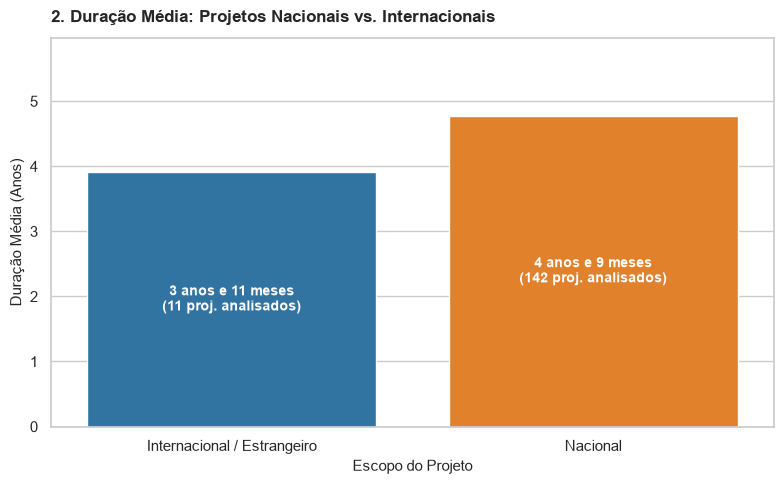

In [104]:
# 3. Plotagem
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(
    data=dur_escopo,
    x='escopo_fomento',
    y='mean',
    palette=['#1f77b4', '#ff7f0e'],
    ax=ax,
)

for i, row in dur_escopo.iterrows():
  val = row['mean']
  rotulo = f"{row['rotulo_duracao']}\n({row['count']} proj. analisados)"
  ax.text(
      i,
      val / 2,
      rotulo,
      ha='center',
      va='center',
      color='white',
      fontweight='bold',
      fontsize=10,
  )

ax.set_title(
    '2. Duração Média: Projetos Nacionais vs. Internacionais',
    loc='left',
    y=1.02,
    fontsize=12,
    fontweight='bold',
)
ax.set_xlabel('Escopo do Projeto', fontsize=11)
ax.set_ylabel('Duração Média (Anos)', fontsize=11)
ax.set_ylim(0, max(dur_escopo['mean']) * 1.25)

plt.tight_layout()
plt.show()

#### professores com maiores quantitativos de projetos internacionais

In [ ]:
col_orientador = 'professor' if 'professor' in df.columns else 'coordenador'
df_int = df[df['escopo_fomento'] == 'Internacional / Estrangeiro'].copy()

# 1. Agrupar garantindo exatamente 1 linha única por professor
prof_int = (
    df_int.groupby(col_orientador)
    .agg(
        qtd=('projeto', 'count'),
        duracao_media=('duracao_est', 'mean'),
        linha_principal=(
            'area_pgcomp_clean',
            lambda x: x.mode()[0] if not x.empty else 'Não informado',
        ),
    )
    .reset_index()
)

# 2. Ordenar e selecionar os Top 10
prof_int = prof_int.sort_values(by='qtd', ascending=False).head(10)
prof_int['rotulo_duracao'] = prof_int['duracao_media'].apply(format_anos_meses)


C:\Users\ferna\AppData\Local\Temp\ipykernel_14152\1228189148.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


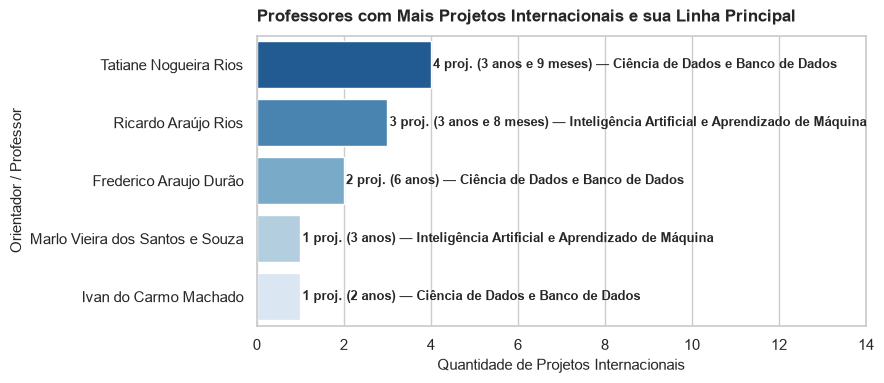

In [112]:
# 3. Plotagem sem barras de erro (errorbar=None)
fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(
    data=prof_int,
    y=col_orientador,
    x='qtd',
    palette='Blues_r',
    errorbar=None,
    ax=ax,
)

# 4. Adicionar rótulos formatados ao lado de cada barra
max_qtd = prof_int['qtd'].max()
for i, row in prof_int.reset_index(drop=True).iterrows():
  qtd = int(row['qtd'])
  dur_txt = row['rotulo_duracao']
  linha_txt = row['linha_principal']

  ax.text(
      qtd + 0.05,
      i,
      f'{qtd} proj. ({dur_txt}) — {linha_txt}',
      va='center',
      ha='left',
      fontsize=9,
      fontweight='bold',
  )

# 5. Ajustar títulos, eixos e expandir xlim para caber a legenda lateral
ax.set_title(
    'Professores com Mais Projetos Internacionais e sua Linha Principal',
    loc='left',
    x=0,
    y=1.02,
    fontsize=12,
    fontweight='bold',
)
ax.set_xlabel('Quantidade de Projetos Internacionais', fontsize=11)
ax.set_ylabel('Orientador / Professor', fontsize=11)

# Aumenta a margem do eixo X para dar espaço ao texto longo
ax.set_xlim(0, max_qtd * 3.5)

plt.tight_layout()
plt.show()